# Funding distribution and growth heatmaps

How are funding amounts distributed, and how does each recipient's funding change?

**Scope:** The distribution section pools all cleaned recipient-year records from 2020-2025. The growth section uses the shared legal-form cohort, with one recipient per heatmap row and separate annual and fixed 2020-2025 comparisons.

The opening section describes the distribution across all cleaned recipient-year records. The later growth section changes scope to the shared legal-form cohort and provides recipient-level heatmaps. Notebook 07 examines those growth patterns in more detail.

The [Methodology](../METHODOLOGY.md) documents definitions and correction policies. The [Project overview](../README.md) describes the notebook sequence and dataset rebuild process.

## Funding records and chart settings

The inputs are the cleaned funding data and shared chart settings.

In [ ]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Locate the checkout from the project folder or a notebook subfolder.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "analysis_helpers.py").is_file()
     and (p / "config" / "sources.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from chart_style import apply_chart_style, colors_from_style, growth_cmap_from_style, load_chart_style

chart_style = load_chart_style(PROJECT_ROOT)
apply_chart_style(chart_style)
CHART_COLORS = colors_from_style(chart_style)
GROWTH_CMAP = growth_cmap_from_style(chart_style)
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

vmi = pd.read_csv(INTERIM_DIR / "vmi_support_by_recipient.csv", low_memory=False, dtype={"recipient_code": "string"})

vmi["tax_year"] = pd.to_numeric(vmi["tax_year"], errors="coerce")
vmi["recipient_code"] = vmi["recipient_code"].astype("string").str.strip()
vmi["requests"] = pd.to_numeric(vmi["requests"], errors="coerce")
vmi["calculated_pmd_eur"] = pd.to_numeric(vmi["calculated_pmd_eur"], errors="coerce")
vmi["legal_form_clean"] = vmi["legal_form"].fillna("Unknown").str.strip()

vmi.head()




,tax_year,recipient_municipality,recipient_code,recipient_name,legal_form,requests,calculated_pmd_eur,legal_form_clean
0,2025,Kauno m. sav.,191678556,Socialinių inovacijų fondas,Labdaros ir paramos fondas,7,604.80,Labdaros ir paramos fondas
1,2025,Plungės r. sav.,170075590,"Sporto klubas ""Makabi""",Asociacija,4,192.18,Asociacija
2,2025,Kauno m. sav.,193158860,Moters užimtumo informacijos centras,Asociacija,4,316.10,Asociacija
3,2025,Vilniaus m. sav.,124467262,"Paramos fondas ""Švietimo ir tyrimų institutas""",Labdaros ir paramos fondas,19,985.02,Labdaros ir paramos fondas
4,2025,Jurbarko r. sav.,191250833,Skirsnemunės Šv. Jurgio parapija,Tradicinė religinė bendruomenė ar bendrija,9,788.37,Tradicinė religinė bendruomenė ar bendrija


## Amount statistics and percentiles

The summary distinguishes record counts, missing values and zeros from monetary statistics. Percentiles pool years and include recorded zero amounts; they describe recipient-year records, not a ranking of unique recipients.

In [2]:
pmd = vmi["calculated_pmd_eur"].dropna()

pmd_summary = pd.DataFrame({
    "measure": ["records", "missing", "zero_values", "total_pmd_eur", "mean", "median", "std", "min", "max"],
    "value": [
        len(vmi),
        vmi["calculated_pmd_eur"].isna().sum(),
        (vmi["calculated_pmd_eur"] == 0).sum(),
        pmd.sum(),
        pmd.mean(),
        pmd.median(),
        pmd.std(),
        pmd.min(),
        pmd.max(),
    ]
})

pmd_summary

,measure,value
0,records,1.207340e+05
1,missing,0.000000e+00
2,zero_values,5.630000e+02
3,total_pmd_eur,1.897147e+08
4,mean,1.571345e+03
5,median,3.747200e+02
6,std,2.124856e+04
7,min,0.000000e+00
8,max,3.068048e+06


In [3]:
percentile_table = pd.DataFrame({
    "percentile": ["25%", "50%", "75%", "90%", "95%", "99%"],
    "calculated_pmd_eur": [pmd.quantile(q) for q in [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]]
})

percentile_table

,percentile,calculated_pmd_eur
0,25%,136.9000
1,50%,374.7200
2,75%,953.5750
3,90%,2146.8770
4,95%,3656.8775
5,99%,12782.0248


## Annual funding context

These totals and the line chart show funding across all recorded recipients in each year. They are not restricted to the later growth cohort.

In [4]:
pmd_by_year = (
    vmi.groupby("tax_year", as_index=False)["calculated_pmd_eur"]
    .sum()
    .sort_values("tax_year")
)

pmd_by_year

,tax_year,calculated_pmd_eur
0,2020,21654753.19
1,2021,27843175.86
2,2022,29202852.20
3,2023,33985135.12
4,2024,36904168.23
5,2025,40124624.74


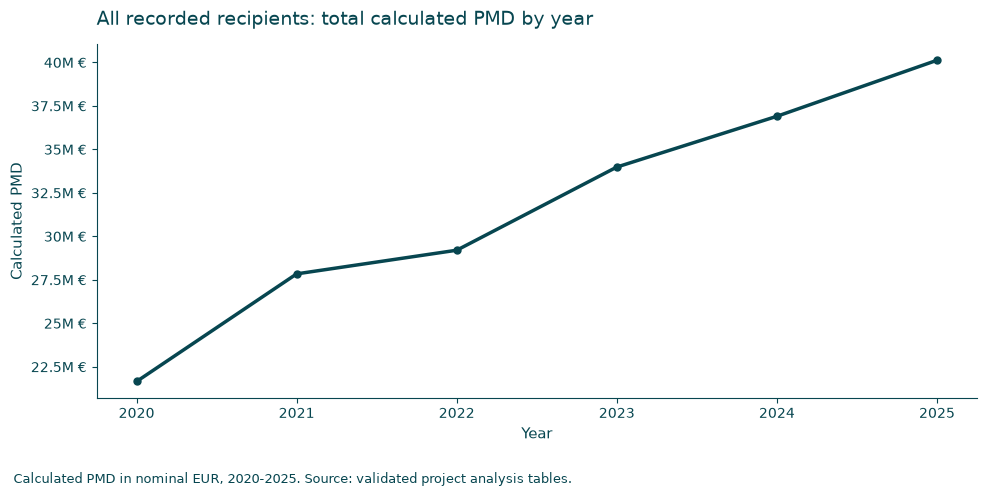

,tax_year,calculated_pmd_eur
0,2020,21654753.19
1,2021,27843175.86
2,2022,29202852.20
3,2023,33985135.12
4,2024,36904168.23
5,2025,40124624.74


In [5]:
from chart_style import finish_chart, growth_boxplot, contrast_text

pmd_by_year = pmd_by_year.set_index("tax_year").reindex(range(2020, 2026)).rename_axis("tax_year").reset_index()

plt.figure(figsize=(10, 5))
plt.plot(pmd_by_year["tax_year"], pmd_by_year["calculated_pmd_eur"], marker="o", linewidth=2.5, color=CHART_COLORS["primary"])
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x/1_000_000:.1f}M €"))
plt.title("All recorded recipients: total calculated PMD by year")
plt.xlabel("Year")
plt.ylabel("Calculated PMD")
plt.grid(False, which="both")

finish_chart(plt.gcf(), 'Calculated PMD in nominal EUR, 2020-2025. Source: validated project analysis tables.')

display(pmd_by_year)


## Pooled positive-amount thresholds

These thresholds pool positive recipient-year amounts across years. The legacy field `share_of_recipients` refers to shares of these records, not unique organizations. These differ from the separate annual top-1% thresholds used in notebooks 04-06, and ties can change the proportion above a threshold.

In [6]:
pmd_positive = pmd[pmd > 0]
key_shares = [50, 25, 10, 5, 1]

thresholds = pd.DataFrame({
    "share_of_recipients": key_shares,
    "minimum_pmd_eur": [np.percentile(pmd_positive, 100 - s) for s in key_shares]
})

thresholds

,share_of_recipients,minimum_pmd_eur
0,50,378.080
1,25,958.145
2,10,2154.170
3,5,3670.940
4,1,12829.634


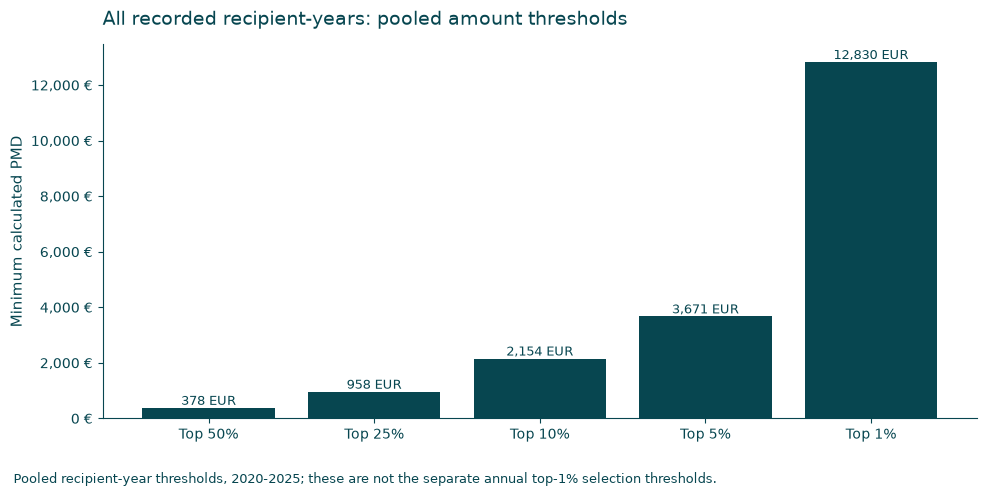

,share_of_recipients,minimum_pmd_eur
0,50,378.080
1,25,958.145
2,10,2154.170
3,5,3670.940
4,1,12829.634


In [7]:
from chart_style import finish_chart, growth_boxplot, contrast_text

plt.figure(figsize=(10, 5))
bars = plt.bar("Top " + thresholds["share_of_recipients"].astype(str) + "%", thresholds["minimum_pmd_eur"], color=CHART_COLORS["primary"])

for bar, value in zip(bars, thresholds["minimum_pmd_eur"]):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{value:,.0f} EUR", ha="center", va="bottom", fontsize=9)

plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f} €"))
plt.title("All recorded recipient-years: pooled amount thresholds")
plt.ylabel("Minimum calculated PMD")

finish_chart(plt.gcf(), 'Pooled recipient-year thresholds, 2020-2025; these are not the separate annual top-1% selection thresholds.')

display(thresholds)


## Recipient growth within the shared cohort

The remaining section retains recipient-year records whose legal form is observed in 2025. This is a data-presence rule, not proof of legal eligibility or a requirement that every recipient survives to 2025. Annual changes require consecutive years; fixed-period changes compare 2020 with 2025. Missing observations remain missing.

In [8]:
from IPython.display import HTML
from matplotlib.colors import LinearSegmentedColormap

vmi_all = pd.read_csv(PROCESSED_DIR / "recipient_analysis.csv", low_memory=False, dtype={"recipient_code": "string"})

vmi_all["tax_year"] = pd.to_numeric(vmi_all["tax_year"], errors="coerce")
vmi_all["recipient_code"] = vmi_all["recipient_code"].astype("string").str.strip()
vmi_all["requests"] = pd.to_numeric(vmi_all["requests"], errors="coerce")
vmi_all["calculated_pmd_eur"] = pd.to_numeric(vmi_all["calculated_pmd_eur"], errors="coerce")
vmi_all["legal_form_clean"] = vmi_all["legal_form"].fillna("Unknown").str.strip()

from cohort import START_YEAR, END_YEAR, LEGAL_FORM_REFERENCE_YEAR, filter_recipient_cohort, show_cohort_report
vmi_filtered, cohort_yearly_report, excluded_legal_forms, legal_form_changes = filter_recipient_cohort(vmi_all)
show_cohort_report(cohort_yearly_report, excluded_legal_forms, legal_form_changes)


from growth_analysis import build_growth_analysis, growth_table as make_growth_table, render_growth_heatmap, render_short_histories
from cohort import START_YEAR, END_YEAR

recipient_year_amounts, period_summary = build_growth_analysis(vmi_filtered, start=START_YEAR, end=END_YEAR)
growth_table, recipient_labels = make_growth_table(recipient_year_amounts, period_summary, START_YEAR, END_YEAR)
growth_table.head()

Legal forms observed in 2025; analysis years 2020-2025.
Filtering applies to recipient-year legal forms, not survival of each recipient in 2025.
Yearly inclusion and exclusion totals (amounts sum known values):


,tax_year,all_recipients,all_rows,all_pmd_eur,included_recipients,included_rows,included_pmd_eur,excluded_recipients,excluded_rows,excluded_pmd_eur,excluded_pmd_share,missing_amount_rows
0,2020,23240,23240,"21,654,753.19",16748,16748,"17,253,053.18",6492,6492,"4,401,700.01",20.33%,0
1,2021,22798,22798,"27,843,175.86",16325,16325,"22,940,811.40",6473,6473,"4,902,364.46",17.61%,0
2,2022,22147,22147,"29,202,852.20",15744,15744,"24,254,670.09",6403,6403,"4,948,182.11",16.94%,0
3,2023,22555,22555,"33,985,135.12",16252,16252,"28,543,797.48",6303,6303,"5,441,337.64",16.01%,0
4,2024,14511,14511,"36,904,168.23",14503,14503,"36,895,489.41",8,8,"8,678.82",0.02%,0
5,2025,15483,15483,"40,124,624.74",15483,15483,"40,124,624.74",0,0,0.00,0.00%,0


Excluded legal forms; absence is not evidence of legal ineligibility:


,legal_form_clean,exclusion_reason,recipients,rows,pmd_eur
0,Bendrija,Not observed in reference year,4048,13548,"4,267,247.25"
1,Biudžetinė įstaiga,Not observed in reference year,2436,8977,"13,942,264.28"
2,Mažoji bendrija,Not observed in reference year,15,54,"16,006.40"
3,"Prekybos, pramonės ir amatų rūmai",Not observed in reference year,4,13,"6,139.28"
4,Regiono plėtros taryba,Not observed in reference year,1,3,353.56
5,Sodininkų bendrija,Not observed in reference year,803,2869,"1,330,995.52"
6,Uždaroji akcinė bendrovė,Not observed in reference year,26,87,"83,911.66"
7,Šeimyna,Not observed in reference year,45,128,"55,345.09"


Recipients with multiple recorded legal forms: 0
The full legal_form_changes table retains every affected recipient-year; preview:


,recipient_code,recipient_name,tax_year,legal_form_clean,included_in_cohort


A recipient can appear in both inclusion groups within a year if its source records have different forms.


tax_year,2021,2022,2023,2024,2025,Growth 2020-2025,Annualized 2020-2025
Recipient,,,,,,,
304772988,4334.000000,NaN,NaN,NaN,NaN,43471.000000,7.465292
191378498,8.076923,227.398305,2.566101,0.178722,0.789976,15597.538462,5.896310
303122222,21.500000,0.200000,178.129630,-0.570144,4.671236,11789.500000,5.520884
293339790,-1.000000,NaN,NaN,NaN,-0.537630,8336.000000,5.084179
192104272,466.230769,0.000659,2.032247,0.545524,1.044481,4478.615385,4.373387


## Fixed-period comparison coverage

These counts identify recipients with available fixed-period percentage growth and those without a comparable baseline or history. Log growth additionally requires positive ending funding.

In [9]:
period_summary.groupby("fixed_period_status").agg(recipients=("recipient_code", "nunique"))

,recipients
fixed_period_status,
Available,10381
Invalid or zero baseline,27
Missing endpoint,12993


## Percentage-growth heatmap

A year column compares that year with the preceding calendar year. A zero ending amount can produce -100%; a missing year is not zero. The current theme uses purple for decline, pink for neutral and green for growth, with light grey for unavailable comparisons. The first 30 rows are an ordered preview, not a representative sample. The exported HTML contains the full table and the preview uses its color scale.

In [10]:
render_growth_heatmap(growth_table, recipient_labels, GROWTH_CMAP, CHART_COLORS, output_path=PROJECT_ROOT / "outputs" / "heatmaps" / "02_percentage_growth.html", preview_rows=30)

tax_year,2021,2022,2023,2024,2025,Growth 2020-2025,Annualized 2020-2025
Recipient,,,,,,,
Asociacija Lietuvos suaugusių alkoholikų vaikų bendrija,"+433,400%",Unavailable,Unavailable,Unavailable,Unavailable,"+4,347,100%",+746.5%
Kauno miesto musulmonų religinė bendruomenė,+807.7%,"+22,739.8%",+256.6%,+17.9%,+79%,"+1,559,753.8%",+589.6%
Lengvosios atletikos asociacija,"+2,150%",+20%,"+17,813%",-57%,+467.1%,"+1,178,950%",+552.1%
"Krikščionių misija ""Aušra""",-100%,Unavailable,Unavailable,Unavailable,-53.8%,"+833,600%",+508.4%
Lazdijų sentikių religinė bendruomenė,"+46,623.1%",+0.1%,+203.2%,+54.6%,+104.4%,"+447,861.5%",+437.3%
Geidžiūnų bendruomenė,"+87,155.6%",-1.3%,+116%,+12.7%,+65.3%,"+346,422.2%",+410.4%
"Labdaros ir paramos fondas ""VILTIES KALNAS""","+47,162.5%",-94.9%,"+3,062.5%",-7.7%,+371.3%,"+330,200%",+405.6%
Lietuvių skalikų augintojų sąjunga,"+12,818%",-98.3%,"+12,972.9%",+757.6%,+21.9%,"+292,294%",+393.4%
"Sporto klubas ""Šilalės lūšis""",Unavailable,Unavailable,"+2,201.2%",+4.6%,-30.7%,"+277,096.8%",+388.2%


## Natural-log growth

Log growth is ln(ending amount / starting amount), with strictly positive amounts at both endpoints. Zero endings remain unavailable here, not neutral. Log scaling compresses large ratios but does not eliminate sensitivity to small starting amounts. The next cell exports the full log heatmap.

In [11]:
growth_log_table, log_recipient_labels = make_growth_table(
    recipient_year_amounts, period_summary, START_YEAR, END_YEAR, logarithmic=True
)
growth_log_table.head()

tax_year,2021,2022,2023,2024,2025,Growth 2020-2025,Annualized 2020-2025
Recipient,,,,,,,
304772988,8.374477,NaN,NaN,NaN,NaN,10.679872,2.135974
191378498,2.205735,5.431091,1.271473,0.164431,0.582202,9.654933,1.930987
303122222,3.113515,0.182322,5.188110,-0.844304,1.735407,9.375049,1.875010
293339790,NaN,NaN,NaN,NaN,-0.771389,9.028459,1.805692
192104272,6.146823,0.000658,1.109304,0.435363,0.715144,8.407292,1.681458


In [12]:
render_growth_heatmap(growth_log_table, log_recipient_labels, GROWTH_CMAP, CHART_COLORS, logarithmic=True, output_path=PROJECT_ROOT / "outputs" / "heatmaps" / "02_log_growth.html", preview_rows=30)

tax_year,2021,2022,2023,2024,2025,Growth 2020-2025,Annualized 2020-2025
Recipient,,,,,,,
Asociacija Lietuvos suaugusių alkoholikų vaikų bendrija,+8.37,Unavailable,Unavailable,Unavailable,Unavailable,+10.68,+2.14
Kauno miesto musulmonų religinė bendruomenė,+2.21,+5.43,+1.27,+0.16,+0.58,+9.65,+1.93
Lengvosios atletikos asociacija,+3.11,+0.18,+5.19,-0.84,+1.74,+9.38,+1.88
"Krikščionių misija ""Aušra""",Unavailable,Unavailable,Unavailable,Unavailable,-0.77,+9.03,+1.81
Lazdijų sentikių religinė bendruomenė,+6.15,+0.00066,+1.11,+0.44,+0.72,+8.41,+1.68
Geidžiūnų bendruomenė,+6.77,-0.01,+0.77,+0.12,+0.5,+8.15,+1.63
"Labdaros ir paramos fondas ""VILTIES KALNAS""",+6.16,-2.98,+3.45,-0.08,+1.55,+8.1,+1.62
Lietuvių skalikų augintojų sąjunga,+4.86,-4.1,+4.87,+2.15,+0.2,+7.98,+1.6
"Sporto klubas ""Šilalės lūšis""",Unavailable,Unavailable,+3.14,+0.05,-0.37,+7.93,+1.59


## Separate comparisons for shorter histories

This report shows observed-period comparisons for recipients without the full fixed-period history. Different observation intervals must not be ranked as if they all covered 2020-2025. A single observed year provides no growth comparison.

In [13]:
render_short_histories(period_summary, START_YEAR, END_YEAR, output_path=PROJECT_ROOT / "outputs" / "heatmaps" / "02_short_histories.html", preview_rows=30)

Recipient,First year,Last year,Observed years,Elapsed years,Observed-period growth,Annualized observed growth,History status
Lietuvos žemės ūkio bendrovių asociacija,2020,2023,4,3,177.3%,40.5%,Available
Asociacija LATGA,2022,2025,4,3,3475.5%,229.4%,Available
"Viešoji įstaiga ""Vilniaus verslo konsultacinis centras""",2020,2021,2,1,75.9%,75.9%,Available
Viešoji įstaiga Thomo Manno kultūros centras,2020,2022,3,2,-79.8%,-55.0%,Available
Viešoji įstaiga LIETUVOS INOVACIJŲ CENTRAS,2020,2023,4,3,15.3%,4.9%,Available
"Viešoji įstaiga ""Humana People to People Baltic""",2020,2020,1,0,Unavailable,Unavailable,Insufficient history
Janinos Monkutės Marks labdaros ir paramos fondas,2020,2024,5,4,-85.2%,-37.9%,Available
VIEŠOJI ĮSTAIGA BALTIJOS ŠALIŲ STRATEGINIO VYSTYMO INSTITUTAS,2020,2023,4,3,98.0%,25.6%,Available
KULTŪROS VYSTYMO IR ŠVIETIMO VIEŠOJI ĮSTAIGA,2020,2024,5,4,49.6%,10.6%,Available
"Viešoji įstaiga ""FURNITEST""",2020,2023,4,3,-85.2%,-47.1%,Available


## Reading the results together

Pooled thresholds describe the pooled distribution; annual thresholds identify each year's top recipients. Common endpoints provide comparable whole-period growth measures.

[Previous notebook](01_exploratory_analysis.ipynb) | [Next notebook](03_legal_forms_analysis.ipynb) | [Reading guide](../README.md#reading-order)